In [130]:
import os
import xarray as xr
from datetime import timedelta
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import scipy.stats as stats
import pandas as pd
import colormaps as cmaps
import cartopy.crs as ccrs

In [131]:
#custom colormap
import pickle

# Load the colormap
with open("fog_colormap.pkl", "rb") as f:
    fog_cmap = pickle.load(f)

In [132]:
cloud_study = xr.open_dataset("data/cesm_StdModel/cloud_std_study.nc")
cloud_study = cloud_study.CLOUD
cloud_study

<xarray.DataArray 'CLOUD' (time: 600, lat: 192, lon: 288)> Size: 133MB
[33177600 values with dtype=float32]
Coordinates:
  * lat      (lat) float64 2kB -90.0 -89.06 -88.12 -87.17 ... 88.12 89.06 90.0
  * lon      (lon) float64 2kB 0.0 1.25 2.5 3.75 5.0 ... 355.0 356.2 357.5 358.8
  * time     (time) datetime64[ns] 5kB 1955-01-16 1955-02-13 ... 2004-12-16
    lev      float64 8B ...
    month    (time) int64 5kB ...
    year     (time) int64 5kB ...
Attributes:
    mdims:         1
    units:         fraction
    long_name:     Cloud fraction
    cell_methods:  time: mean

In [133]:
#grid data
lat_bins = np.arange(-90, 91, 5)
lon_bins = np.arange(0, 361, 5)

lat_centers = lat_bins[:-1] + 2.5
lon_centers = lon_bins[:-1] + 2.5

cloud_study_coarse = cloud_study.interp({"lat":lat_centers, "lon":lon_centers})
cloud_study_coarse

<xarray.DataArray 'CLOUD' (time: 600, lat: 36, lon: 72)> Size: 12MB
array([[[0.25396306, 0.25973236, 0.26440654, ..., 0.20734362,
         0.22451959, 0.23952464],
        [0.22594745, 0.20184294, 0.16730699, ..., 0.29313592,
         0.24517083, 0.22960254],
        [0.09387631, 0.08403551, 0.13689781, ..., 0.09253962,
         0.10548303, 0.09865723],
        ...,
        [0.42112739, 0.18216947, 0.40015861, ..., 0.4173181 ,
         0.56787151, 0.59199374],
        [0.59280647, 0.60597173, 0.58144019, ..., 0.55869891,
         0.51962261, 0.54718244],
        [0.6165308 , 0.61232276, 0.60835677, ..., 0.61271455,
         0.60730569, 0.61207062]],

       [[0.38069485, 0.39664117, 0.39487301, ..., 0.28840981,
         0.31954486, 0.3593642 ],
        [0.36516936, 0.38027725, 0.32878982, ..., 0.36433219,
         0.32949032, 0.3262036 ],
        [0.22760939, 0.21167366, 0.237215  , ..., 0.12286375,
         0.19461168, 0.21267668],
...
        [0.21748267, 0.0387754 , 0.2173701 , ..., 0.39789331,
         0.48891746, 0.48178504],
        [0.47684328, 0.52686212, 0.55110547, ..., 0.3789197 ,
         0.39667541, 0.42407045],
        [0.47522135, 0.47778362, 0.47872055, ..., 0.44100407,
         0.44465243, 0.45631869]],

       [[0.16320578, 0.16236933, 0.16528866, ..., 0.15948155,
         0.15806758, 0.16308061],
        [0.07508517, 0.06890044, 0.0745905 , ..., 0.04187294,
         0.02959593, 0.04761442],
        [0.04453059, 0.12123633, 0.18361833, ..., 0.0506851 ,
         0.04317118, 0.02492729],
        ...,
        [0.40523772, 0.16627519, 0.42354916, ..., 0.55151959,
         0.6981952 , 0.74373859],
        [0.72470427, 0.69187726, 0.68364609, ..., 0.61797405,
         0.73897767, 0.76272182],
        [0.72232427, 0.72810666, 0.73402736, ..., 0.72281305,
         0.71442853, 0.71812235]]], shape=(600, 36, 72))
Coordinates:
  * time     (time) datetime64[ns] 5kB 1955-01-16 1955-02-13 ... 2004-12-16
    lev      float64 8B ...
    month    (time) int64 5kB ...
    year     (time) int64 5kB ...
  * lat      (lat) float64 288B -87.5 -82.5 -77.5 -72.5 ... 72.5 77.5 82.5 87.5
  * lon      (lon) float64 576B 2.5 7.5 12.5 17.5 ... 342.5 347.5 352.5 357.5
Attributes:
    mdims:         1
    units:         fraction
    long_name:     Cloud fraction
    cell_methods:  time: mean

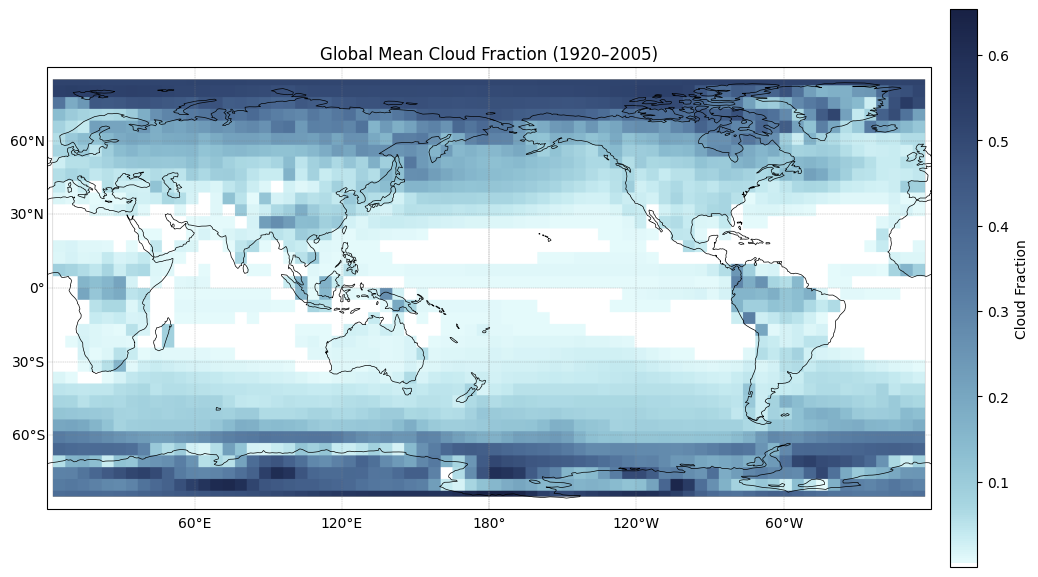

In [134]:
# Compute time mean
global_mean = cloud_study_coarse.mean("time")

# Coordinates
lat = global_mean['lat'].values
lon = global_mean['lon'].values

# Plot
fig, ax = plt.subplots(
    figsize=(12, 8),
    subplot_kw={"projection": ccrs.PlateCarree(central_longitude=180)}
)

im = ax.imshow(
    global_mean,
    origin="lower",
    extent=[lon.min(), lon.max(), lat.min(), lat.max()],
    cmap=fog_cmap,
    vmin=np.nanmin(global_mean),
    vmax=np.nanmax(global_mean),
    transform=ccrs.PlateCarree()
)

ax.set_title("Global Mean Cloud Fraction (1920–2005)")
ax.coastlines(linewidth=0.5)
gl = ax.gridlines(draw_labels=True, linewidth=0.3, color="gray", alpha=0.7, linestyle="--")
gl.right_labels = False
gl.top_labels = False

# Colorbar
cbar = fig.colorbar(im, ax=ax, orientation="vertical", fraction=0.03, pad=0.02)
cbar.set_label("Cloud Fraction")

plt.show()


In [135]:
# mask gridded data
# mask is created and saved to folder in 02visualizeEECRA.ipynb

mask_df = pd.read_csv("data/EECRA/5yr_seasonal_study/mask.csv", sep=',', header=None )
mask = xr.DataArray(mask_df.values, dims=["lat", "lon"])

masked_cloud_study = cloud_study_coarse.where(mask)

masked_cloud_study

<xarray.DataArray 'CLOUD' (time: 600, lat: 36, lon: 72)> Size: 12MB
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
...
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]]], shape=(600, 36, 72))
Coordinates:
  * time     (time) datetime64[ns] 5kB 1955-01-16 1955-02-13 ... 2004-12-16
    lev      float64 8B ...
    month    (time) int64 5kB ...
    year     (time) int64 5kB ...
  * lat      (lat) float64 288B -87.5 -82.5 -77.5 -72.5 ... 72.5 77.5 82.5 87.5
  * lon      (lon) float64 576B 2.5 7.5 12.5 17.5 ... 342.5 347.5 352.5 357.5
Attributes:
    mdims:         1
    units:         fraction
    long_name:     Cloud fraction
    cell_methods:  time: mean

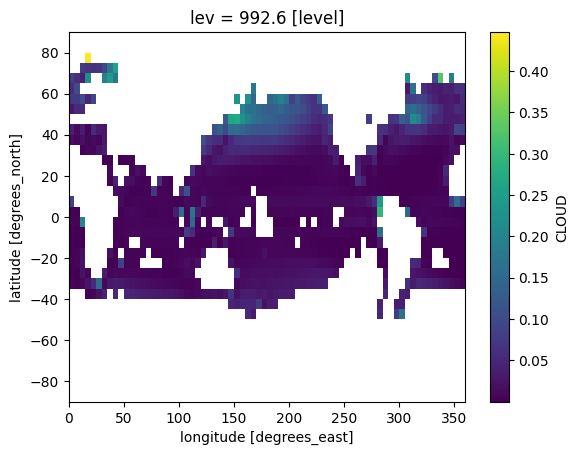

In [136]:
masked_cloud_study.mean("time").plot()

Seasonal Climatology (to check data)

In [137]:
def select_season(data, months, season_name):
    # Filter by month
    season_data = data.where(data.month.isin(months), drop=True)
    
    # For DJF, we need to handle the year roll
    if season_name == 'DJF':
        # Drop December of the last year to avoid incomplete season
        last_month = season_data.time[-1].dt.month.item()
        if last_month == 12:
            # Drop the last time entry if it's December
            season_data = season_data.isel(time=slice(0, -1))
        
    return season_data

djf = select_season(masked_cloud_study, [12, 1, 2], "DJF").mean("time")
mam = select_season(masked_cloud_study, [3, 4, 5], "MAM").mean("time")
jja = select_season(masked_cloud_study, [6, 7, 8], "JJA").mean("time")
son = select_season(masked_cloud_study, [9, 10, 11], "SON").mean("time")

djf_data = djf.values
mam_data = mam.values
jja_data = jja.values
son_data = son.values

In [138]:
djf

<xarray.DataArray 'CLOUD' (lat: 36, lon: 72)> Size: 21kB
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(36, 72))
Coordinates:
    lev      float64 8B 992.6
  * lat      (lat) float64 288B -87.5 -82.5 -77.5 -72.5 ... 72.5 77.5 82.5 87.5
  * lon      (lon) float64 576B 2.5 7.5 12.5 17.5 ... 342.5 347.5 352.5 357.5

In [139]:
#seasonal
"""# Coordinates (for labeling)
lat = djf['lat'].values
lon = djf['lon'].values

fig, axs = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True, 
                        gridspec_kw={'hspace': 0, 'wspace': 0}, 
                        subplot_kw={"projection": ccrs.PlateCarree(central_longitude=180)}, )
fig.suptitle("LENS CESM Surface Cloud (992.6) fraction by Season, 1920 - 2005")

# Set shared color range (optional)
vmin = np.nanmin([djf, mam, jja, son])
vmax = np.nanmax([djf, mam, jja, son])
fog_cmap.set_bad('darkgray')

datasets = [(djf_data, "DJF"), (mam_data, "MAM"), (jja_data, "JJA"), (son_data, "SON")]

for ax, (data, title) in zip(axs.flat, datasets):
    im = ax.imshow(
        data,
        origin="lower",
        extent=[lon.min(), lon.max(), lat.min(), lat.max()],
        cmap=fog_cmap,
        vmin=vmin,
        vmax=vmax,
        transform=ccrs.PlateCarree()
    )
    ax.set_title(title)
    ax.coastlines(linewidth=0.5)
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, color="gray", alpha=0.7, linestyle="--")
    gl.right_labels = False
    gl.top_labels = False

# Add a colorbar
cbar = fig.colorbar(im, ax=axs, orientation='vertical', fraction=0.03, pad=0.02, label='Cloud Fraction')

plt.savefig("dataViz/LENS_Global_Seasonal_Map")
plt.show()"""

'# Coordinates (for labeling)\nlat = djf[\'lat\'].values\nlon = djf[\'lon\'].values\n\nfig, axs = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True, \n                        gridspec_kw={\'hspace\': 0, \'wspace\': 0}, \n                        subplot_kw={"projection": ccrs.PlateCarree(central_longitude=180)}, )\nfig.suptitle("LENS CESM Surface Cloud (992.6) fraction by Season, 1920 - 2005")\n\n# Set shared color range (optional)\nvmin = np.nanmin([djf, mam, jja, son])\nvmax = np.nanmax([djf, mam, jja, son])\nfog_cmap.set_bad(\'darkgray\')\n\ndatasets = [(djf_data, "DJF"), (mam_data, "MAM"), (jja_data, "JJA"), (son_data, "SON")]\n\nfor ax, (data, title) in zip(axs.flat, datasets):\n    im = ax.imshow(\n        data,\n        origin="lower",\n        extent=[lon.min(), lon.max(), lat.min(), lat.max()],\n        cmap=fog_cmap,\n        vmin=vmin,\n        vmax=vmax,\n        transform=ccrs.PlateCarree()\n    )\n    ax.set_title(title)\n    ax.coastlines(linewidth=0.5)\n    gl 

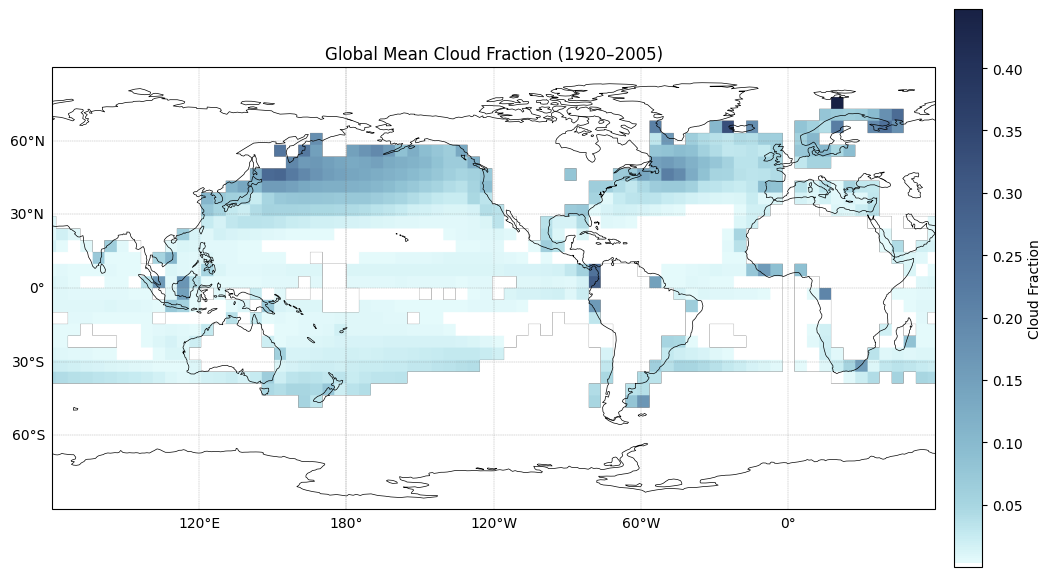

In [140]:
# Compute time mean
global_mean = masked_cloud_study.mean("time")

# Coordinates
lat = global_mean['lat'].values
lon = global_mean['lon'].values

# Plot
fig, ax = plt.subplots(
    figsize=(12, 8),
    subplot_kw={"projection": ccrs.PlateCarree(central_longitude=240)}
)

im = ax.imshow(
    global_mean,
    origin="lower",
    extent=[lon.min(), lon.max(), lat.min(), lat.max()],
    cmap=fog_cmap,
    vmin=np.nanmin(global_mean),
    vmax=np.nanmax(global_mean),
    transform=ccrs.PlateCarree()
)

ax.set_title("Global Mean Cloud Fraction (1920–2005)")
ax.coastlines(linewidth=0.5)
gl = ax.gridlines(draw_labels=True, linewidth=0.3, color="gray", alpha=0.7, linestyle="--")
gl.right_labels = False
gl.top_labels = False

# Colorbar
cbar = fig.colorbar(im, ax=ax, orientation="vertical", fraction=0.03, pad=0.02)
cbar.set_label("Cloud Fraction")

plt.show()


In [141]:
masked_cloud_study

<xarray.DataArray 'CLOUD' (time: 600, lat: 36, lon: 72)> Size: 12MB
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
...
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]]], shape=(600, 36, 72))
Coordinates:
  * time     (time) datetime64[ns] 5kB 1955-01-16 1955-02-13 ... 2004-12-16
    lev      float64 8B ...
    month    (time) int64 5kB 1 2 3 4 5 6 7 8 9 10 11 ... 3 4 5 6 7 8 9 10 11 12
    year     (time) int64 5kB ...
  * lat      (lat) float64 288B -87.5 -82.5 -77.5 -72.5 ... 72.5 77.5 82.5 87.5
  * lon      (lon) float64 576B 2.5 7.5 12.5 17.5 ... 342.5 347.5 352.5 357.5
Attributes:
    mdims:         1
    units:         fraction
    long_name:     Cloud fraction
    cell_methods:  time: mean

NA and NP distributions

In [142]:
#TODO  - lots to fix
lonList = list(lon_centers) 
latList = list(lat_centers)

NP_grid = [lonList.index(122.5), lonList.index(242.5), latList.index(32.5), latList.index(62.5)]
NA_grid= [lonList.index(287.5), lonList.index(357.5), latList.index(37.5), latList.index(67.5)]


#make masked study area cloud df
cloud_study_NP = masked_cloud_study.sel(
    lon=slice(NP_grid[0], NP_grid[1]),
    lat=slice(NP_grid[2], NP_grid[3])
)

cloud_study_NA = masked_cloud_study.sel(
    lon=slice(NA_grid[0], NA_grid[1]),
    lat=slice(NA_grid[2], NA_grid[3])
)

In [143]:
slice(NA_grid[2], NA_grid[3])

slice(25, 31, None)

In [144]:
cloud_study_NA

<xarray.DataArray 'CLOUD' (time: 600, lat: 1, lon: 3)> Size: 14kB
array([[[2.11274848e-02,            nan,            nan]],

       [[1.24341311e-02,            nan,            nan]],

       [[1.76864777e-06,            nan,            nan]],

       ...,

       [[6.23186329e-05,            nan,            nan]],

       [[9.60605244e-05,            nan,            nan]],

       [[5.50820749e-03,            nan,            nan]]],
      shape=(600, 1, 3))
Coordinates:
  * time     (time) datetime64[ns] 5kB 1955-01-16 1955-02-13 ... 2004-12-16
    lev      float64 8B ...
    month    (time) int64 5kB 1 2 3 4 5 6 7 8 9 10 11 ... 3 4 5 6 7 8 9 10 11 12
    year     (time) int64 5kB ...
  * lat      (lat) float64 8B 27.5
  * lon      (lon) float64 24B 57.5 62.5 67.5
Attributes:
    mdims:         1
    units:         fraction
    long_name:     Cloud fraction
    cell_methods:  time: mean

In [145]:
masked_cloud_study

<xarray.DataArray 'CLOUD' (time: 600, lat: 36, lon: 72)> Size: 12MB
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
...
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]]], shape=(600, 36, 72))
Coordinates:
  * time     (time) datetime64[ns] 5kB 1955-01-16 1955-02-13 ... 2004-12-16
    lev      float64 8B ...
    month    (time) int64 5kB 1 2 3 4 5 6 7 8 9 10 11 ... 3 4 5 6 7 8 9 10 11 12
    year     (time) int64 5kB ...
  * lat      (lat) float64 288B -87.5 -82.5 -77.5 -72.5 ... 72.5 77.5 82.5 87.5
  * lon      (lon) float64 576B 2.5 7.5 12.5 17.5 ... 342.5 347.5 352.5 357.5
Attributes:
    mdims:         1
    units:         fraction
    long_name:     Cloud fraction
    cell_methods:  time: mean

In [146]:
cloud_study_NA

<xarray.DataArray 'CLOUD' (time: 600, lat: 1, lon: 3)> Size: 14kB
array([[[2.11274848e-02,            nan,            nan]],

       [[1.24341311e-02,            nan,            nan]],

       [[1.76864777e-06,            nan,            nan]],

       ...,

       [[6.23186329e-05,            nan,            nan]],

       [[9.60605244e-05,            nan,            nan]],

       [[5.50820749e-03,            nan,            nan]]],
      shape=(600, 1, 3))
Coordinates:
  * time     (time) datetime64[ns] 5kB 1955-01-16 1955-02-13 ... 2004-12-16
    lev      float64 8B ...
    month    (time) int64 5kB 1 2 3 4 5 6 7 8 9 10 11 ... 3 4 5 6 7 8 9 10 11 12
    year     (time) int64 5kB ...
  * lat      (lat) float64 8B 27.5
  * lon      (lon) float64 24B 57.5 62.5 67.5
Attributes:
    mdims:         1
    units:         fraction
    long_name:     Cloud fraction
    cell_methods:  time: mean